# Spectral Clustering sur familles de variables
Cette analyse applique le spectral clustering aux familles de descripteurs définies dans `k_means_family.ipynb`.

L’objectif est d’explorer le clustering non supervisé par famille de variables, en comparant un algorithme spectral manuel et l’implémentation `sklearn`.

## Chargement des données et définition des familles
Le notebook charge `Données/X_train_clean.csv` et regroupe les variables numériques en familles de descripteurs.
Ces familles serviront de sous-espaces pour appliquer un clustering spectral par groupe de variables.


In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, SpectralClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.metrics.pairwise import rbf_kernel

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['figure.figsize'] = (14, 8)


In [2]:
# Charger les données nettoyées
X_train = pd.read_csv('Données/X_train_clean.csv')
print(f'Shape du dataset: {X_train.shape}')
display(X_train.head(3))

# Sélection des colonnes numériques utilisées pour les familles
num_cols = X_train.select_dtypes(include=['float64', 'int64']).columns.tolist()
X_num = X_train[num_cols] 

descriptor_families = {
    'PPI': ['PPI_Intersection', 'PPI_Union', 'PPI_Jaccard', 'PPI_Interactant_Asymmetry', 'PPI_Interactant_Mean'],
    'Pfam': ['Pfam_Inter', 'Pfam_Union', 'Pfam_Jaccard', 'Pfam_Asymmetry', 'Pfam_Mean', 'Family_Size'],
    'Ks_et_Ka': ['Ks', 'Ka', 'Ka_Ks', 'Ks_SD', 'Ka_SD', 'Expression_Data_Missing', 'Distance'],
    'TE': ['TE_Coverage_Asymmetry', 'TE_Coverage_Mean', 'TE_Number_Asymmetry', 'TE_Number_Mean', 'TE_Density_Asymmetry', 'TE_Density_Mean', 'TE_Env_Match'],
}

descriptor_families = {k: [c for c in v if c in X_num.columns] for k, v in descriptor_families.items()}
descriptor_families = {k: v for k, v in descriptor_families.items() if v}

print('Familles de descripteurs identifiées :')
for family, cols in descriptor_families.items():
    print(f'  - {family}: {len(cols)} colonnes -> {cols}')

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X_num), columns=X_num.columns)


Shape du dataset: (444, 34)


,Family_Size,PPI_Intersection,PPI_Union,PPI_Jaccard,Pfam_Inter,Pfam_Union,Pfam_Jaccard,Ks,Ka,Ka_Ks,...,Expression_Data_Missing,TE_Env_Pair_TE-free_TE-free,TE_Env_Pair_TE-free_TE-poor,TE_Env_Pair_TE-free_TE-rich,TE_Env_Pair_TE-poor_TE-poor,TE_Env_Pair_TE-poor_TE-rich,TE_Env_Pair_TE-rich_TE-rich,TE_Env_Class_free,TE_Env_Class_half,TE_Env_Class_rich
0,4,1.0,9.0,11.111111,1.0,1.0,1.0,1.8192,0.4049,0.222570,...,0,True,False,False,False,False,False,True,False,False
1,4,1.0,14.0,7.142857,1.0,1.0,1.0,1.9732,0.4109,0.208240,...,0,False,False,True,False,False,False,False,True,False
2,2,12.0,32.0,37.500000,1.0,1.0,1.0,2.3106,0.5092,0.220376,...,0,True,False,False,False,False,False,True,False,False


Familles de descripteurs identifiées :
  - PPI: 5 colonnes -> ['PPI_Intersection', 'PPI_Union', 'PPI_Jaccard', 'PPI_Interactant_Asymmetry', 'PPI_Interactant_Mean']
  - Pfam: 6 colonnes -> ['Pfam_Inter', 'Pfam_Union', 'Pfam_Jaccard', 'Pfam_Asymmetry', 'Pfam_Mean', 'Family_Size']
  - Ks_et_Ka: 7 colonnes -> ['Ks', 'Ka', 'Ka_Ks', 'Ks_SD', 'Ka_SD', 'Expression_Data_Missing', 'Distance']
  - TE: 7 colonnes -> ['TE_Coverage_Asymmetry', 'TE_Coverage_Mean', 'TE_Number_Asymmetry', 'TE_Number_Mean', 'TE_Density_Asymmetry', 'TE_Density_Mean', 'TE_Env_Match']


## Théorie du spectral clustering
Le spectral clustering repose sur une représentation du jeu de données comme un graphe pondéré :
1. On construit la matrice d’adjacence `W` représentant la similarité entre les données.
2. On calcule la matrice de degré `D` et le laplacien `L = D - W` ou le laplacien normalisé `L_sym = D^{-1/2} (D - W) D^{-1/2}`.
3. Les vecteurs propres associés aux plus petites valeurs propres de `L_sym` fournissent un plongement spectral.
4. On applique `k`-means sur ces vecteurs propres normalisés pour obtenir les clusters.



In [3]:
def compute_affinity_matrix(X, gamma=None):
    if gamma is None:
        gamma = 1.0 / X.shape[1] if X.shape[1] > 0 else 1.0
    return rbf_kernel(X, gamma=gamma)

def compute_normalized_laplacian(W):
    degree = np.sum(W, axis=1) # Calcule D_ii pour chaque ligne
    inv_sqrt_degree = np.diag(1.0 / np.sqrt(np.maximum(degree, 1e-12)))
    L = np.eye(W.shape[0]) - inv_sqrt_degree @ W @ inv_sqrt_degree
    return L

def spectral_embedding(L, n_components):
    eigenvalues, eigenvectors = np.linalg.eigh(L)
    return eigenvalues, eigenvectors[:, :n_components]

def spectral_clustering_manual(X, n_clusters, gamma=None, normalize_rows=True):
    W = compute_affinity_matrix(X, gamma=gamma)
    L = compute_normalized_laplacian(W)
    eigenvalues, embedding = spectral_embedding(L, n_clusters)
    if normalize_rows:
        row_norms = np.linalg.norm(embedding, axis=1, keepdims=True)
        embedding = embedding / np.maximum(row_norms, 1e-12)
    kmeans = KMeans(n_clusters=n_clusters, n_init=20, random_state=42)
    labels = kmeans.fit_predict(embedding)
    return kmeans, labels, embedding, eigenvalues, W, L

def evaluate_labels(X, kmeans, labels):
    if len(np.unique(labels)) < 2:
        return {'inertia': np.nan, 'silhouette': np.nan, 'davies_bouldin': np.nan, 'calinski_harabasz': np.nan}
    return {
        'inertia': kmeans.inertia_ if kmeans != 'spectral' else np.nan,
        'silhouette': silhouette_score(X, labels),
        'davies_bouldin': davies_bouldin_score(X, labels),
        'calinski_harabasz': calinski_harabasz_score(X, labels),
    }


## Application du spectral clustering par famille
Ce bloc compare :
- spectral clustering manuel (`normalized laplacian + k-means`),
- spectral clustering `sklearn`,
- K-means sur les données standardisées d’origine.


In [4]:
k_values = [2, 3, 4, 5, 7, 9, 10]
results = {}

for family_name, cols in descriptor_families.items():
    X_family = X_scaled[cols].values
    family_metrics = {
        'manual': {'inertia': [], 'silhouette': [], 'davies_bouldin': [], 'calinski_harabasz': []},
        'sklearn': {'inertia': [], 'silhouette': [], 'davies_bouldin': [], 'calinski_harabasz': []},
        'kmeans': {'inertia': [], 'silhouette': [], 'davies_bouldin': [], 'calinski_harabasz': []},
    }

    gamma = 1.0 / max(len(cols), 1)
    print(f'Traitement de la famille: {family_name} ({len(cols)} colonnes)')

    for k in k_values:
        kmeans_manual, labels_manual, embedding_manual, eigenvalues, W, L = spectral_clustering_manual(X_family, k, gamma=gamma)
        manual_scores = evaluate_labels(X_family, kmeans_manual, labels_manual)

        sklearn_labels = SpectralClustering(
            n_clusters=k, affinity='rbf', gamma=gamma, assign_labels='kmeans', random_state=42, n_init=10
        ).fit_predict(X_family)
        sklearn_scores = evaluate_labels(X_family, 'spectral', sklearn_labels)

        kmeans = KMeans(n_clusters=k, n_init=20, random_state=42, init='k-means++')
        kmeans_labels = kmeans.fit_predict(X_family)
        kmeans_scores = evaluate_labels(X_family, kmeans, kmeans_labels)

        family_metrics['manual']['inertia'].append(manual_scores['inertia'])
        family_metrics['manual']['silhouette'].append(manual_scores['silhouette'])
        family_metrics['manual']['davies_bouldin'].append(manual_scores['davies_bouldin'])
        family_metrics['manual']['calinski_harabasz'].append(manual_scores['calinski_harabasz'])

        family_metrics['sklearn']['inertia'].append(sklearn_scores['inertia'])
        family_metrics['sklearn']['silhouette'].append(sklearn_scores['silhouette'])
        family_metrics['sklearn']['davies_bouldin'].append(sklearn_scores['davies_bouldin'])
        family_metrics['sklearn']['calinski_harabasz'].append(sklearn_scores['calinski_harabasz'])

        family_metrics['kmeans']['inertia'].append(kmeans_scores['inertia'])
        family_metrics['kmeans']['silhouette'].append(kmeans_scores['silhouette'])
        family_metrics['kmeans']['davies_bouldin'].append(kmeans_scores['davies_bouldin'])
        family_metrics['kmeans']['calinski_harabasz'].append(kmeans_scores['calinski_harabasz'])

        print(f'  k={k}: manual silhouette={manual_scores["silhouette"]:.4f}, sklearn silhouette={sklearn_scores["silhouette"]:.4f}, kmeans silhouette={kmeans_scores["silhouette"]:.4f}')

    results[family_name] = family_metrics


Traitement de la famille: PPI (5 colonnes)
  k=2: manual silhouette=0.8765, sklearn silhouette=0.8765, kmeans silhouette=0.7926
  k=3: manual silhouette=0.8129, sklearn silhouette=0.8215, kmeans silhouette=0.7735
  k=4: manual silhouette=0.7262, sklearn silhouette=0.7856, kmeans silhouette=0.5581
  k=5: manual silhouette=0.7183, sklearn silhouette=0.7759, kmeans silhouette=0.6055
  k=7: manual silhouette=0.3928, sklearn silhouette=0.6799, kmeans silhouette=0.5556
  k=9: manual silhouette=0.4531, sklearn silhouette=0.6173, kmeans silhouette=0.5502
  k=10: manual silhouette=0.4564, sklearn silhouette=0.6044, kmeans silhouette=0.5065
Traitement de la famille: Pfam (6 colonnes)
  k=2: manual silhouette=0.8373, sklearn silhouette=0.8373, kmeans silhouette=0.8053
  k=3: manual silhouette=0.8058, sklearn silhouette=0.8058, kmeans silhouette=0.6022
  k=4: manual silhouette=0.7578, sklearn silhouette=0.7864, kmeans silhouette=0.6514
  k=5: manual silhouette=0.7565, sklearn silhouette=0.7836, km

## Visualisation des résultats par famille
On compare les scores d’évaluation et on visualise le plongement spectral pour une famille de démonstration.


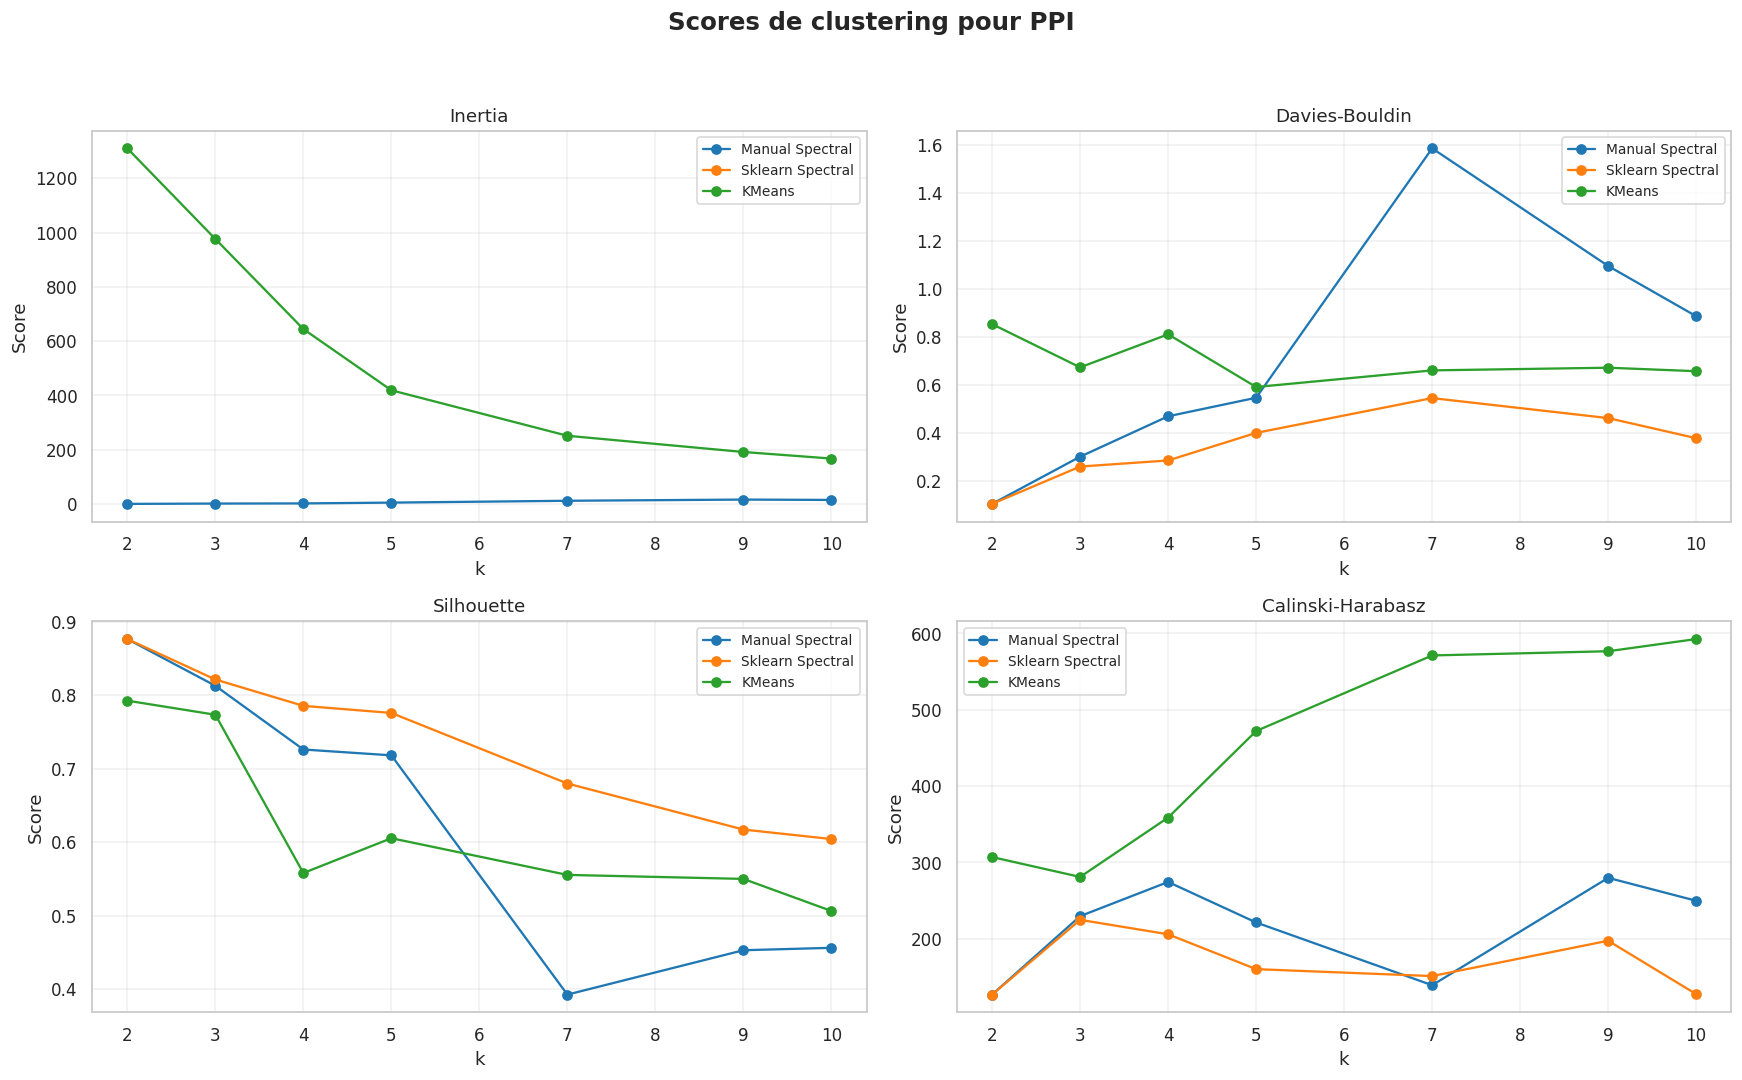

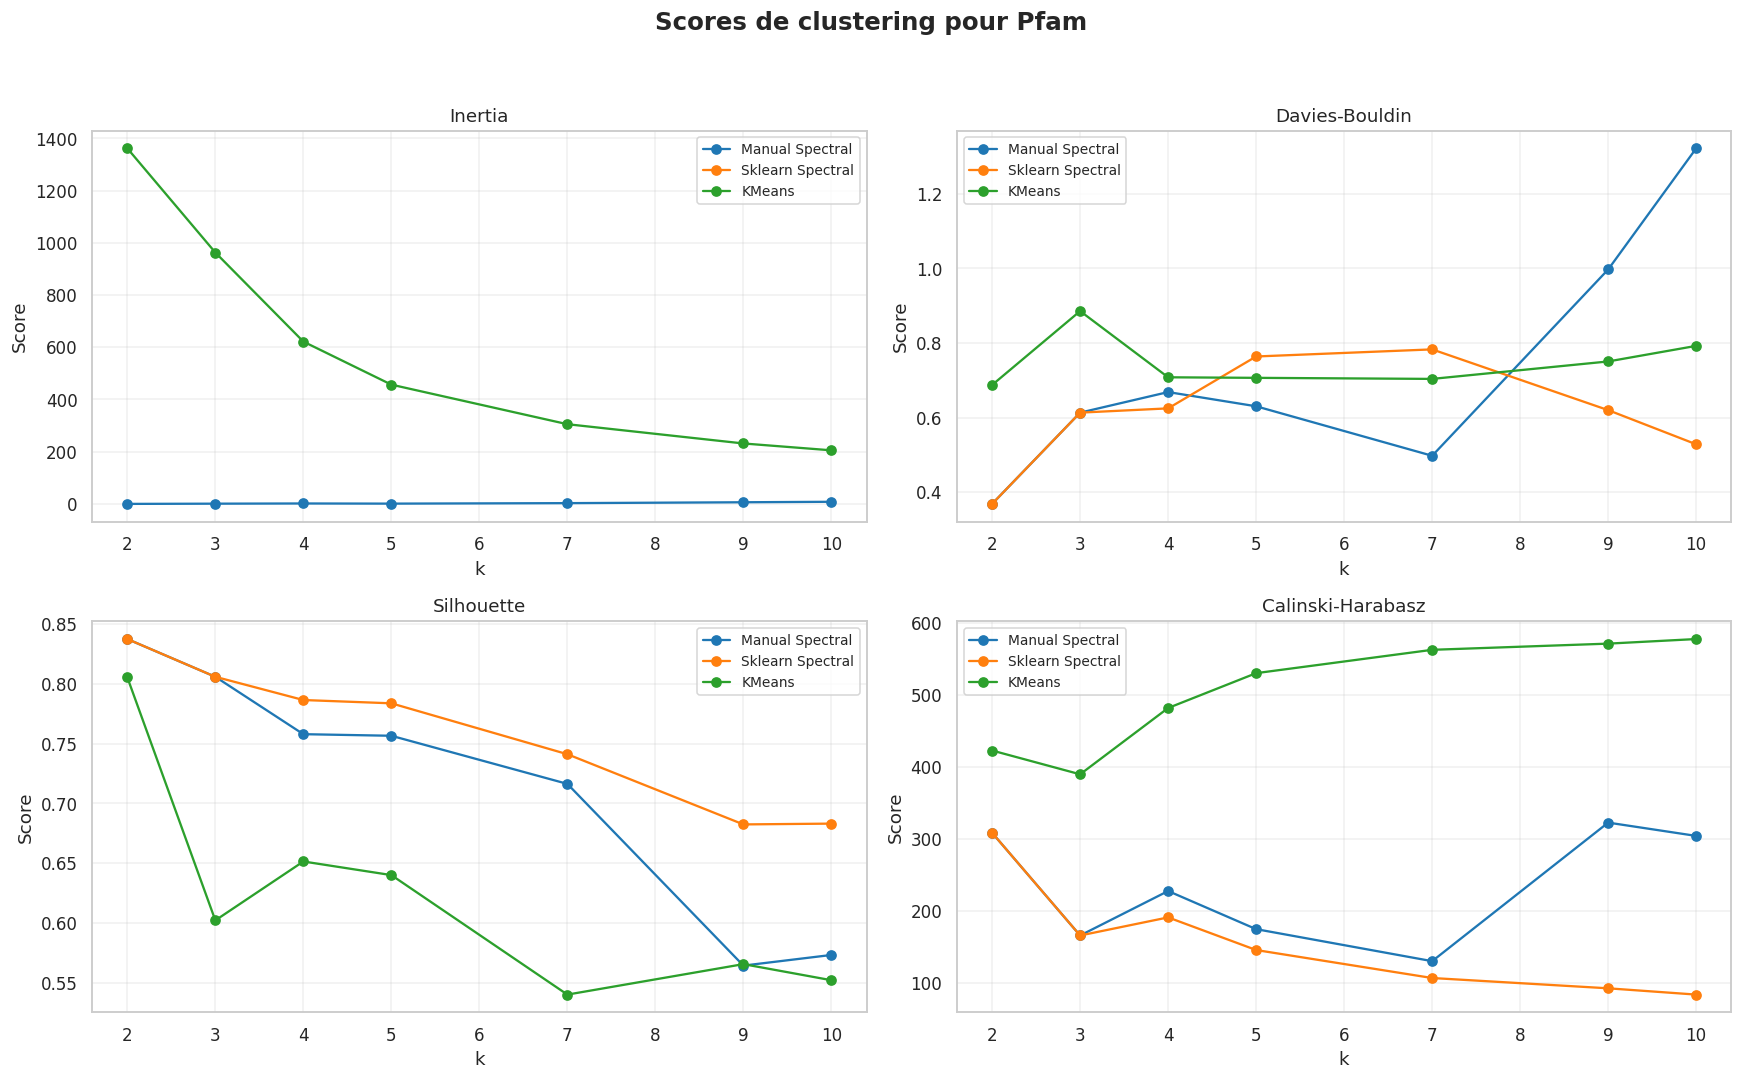

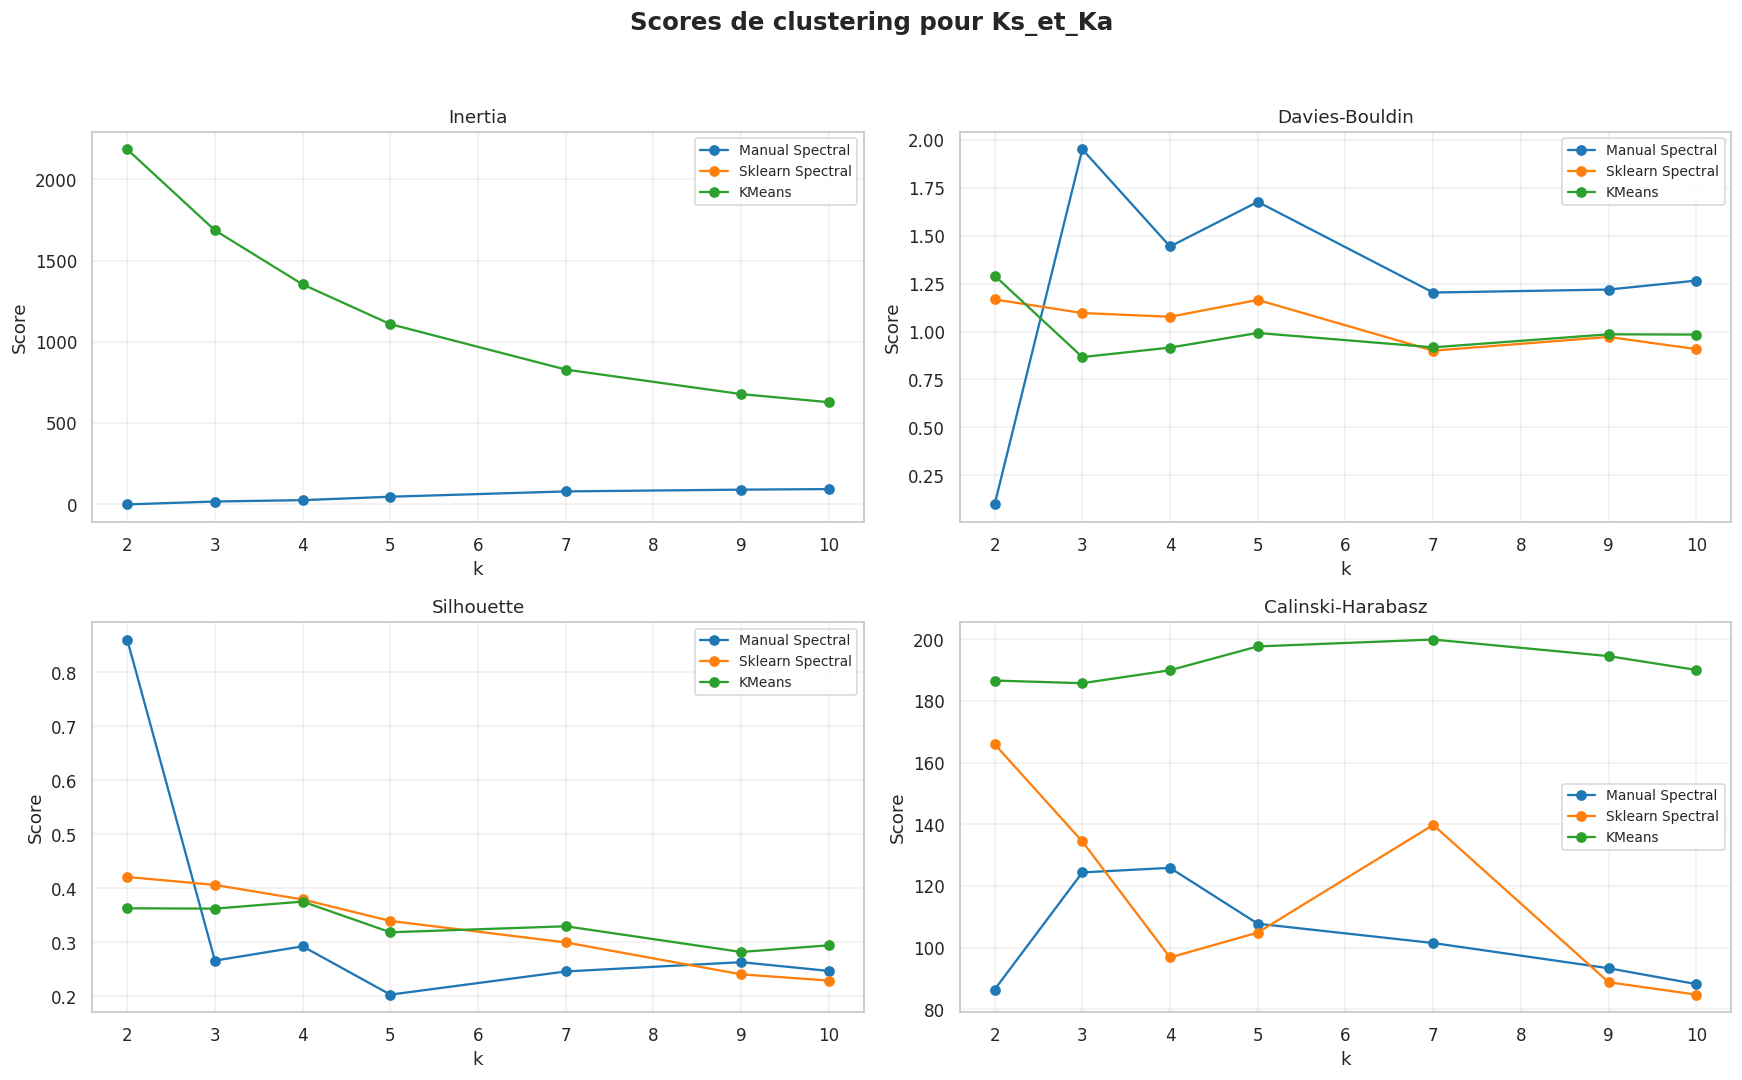

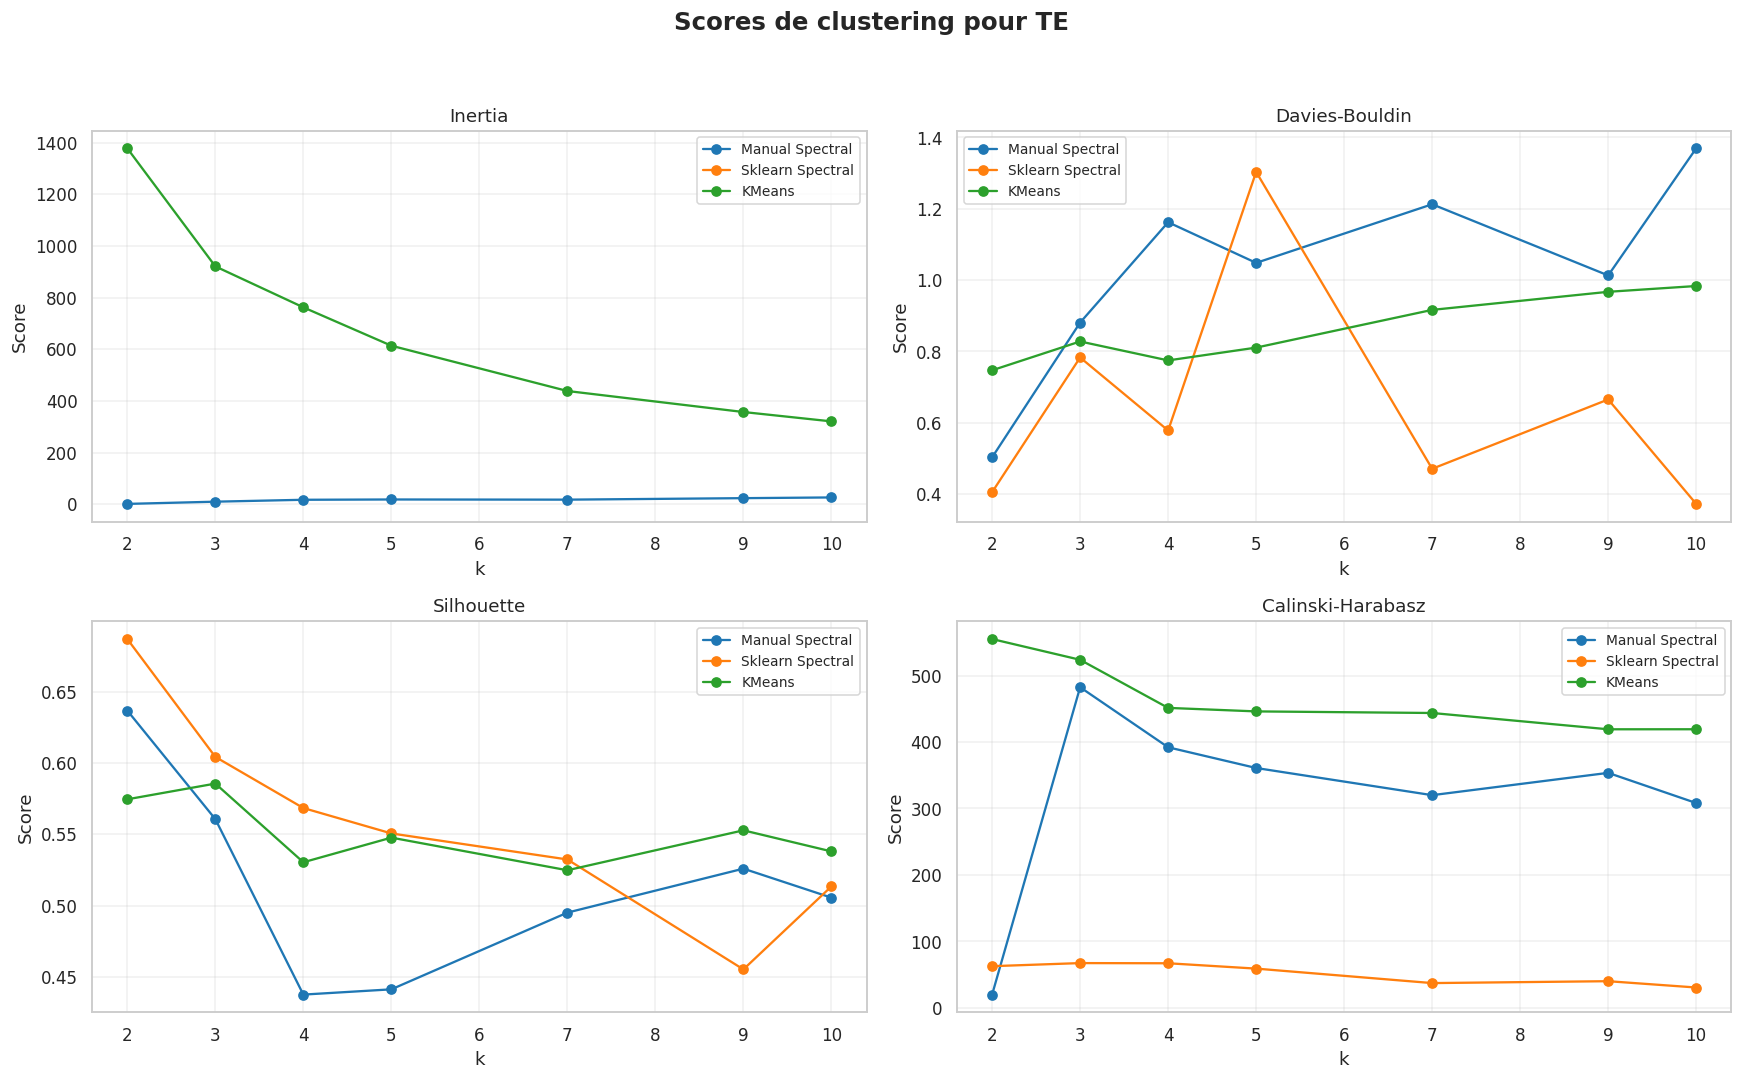

In [5]:
def plot_scores(family_name, results, k_values):
    fig, axes = plt.subplots(2, 2, figsize=(16, 10))
    fig.suptitle(f'Scores de clustering pour {family_name}', fontsize=16, fontweight='bold')

    methods = ['manual', 'sklearn', 'kmeans']
    labels = ['Manual Spectral', 'Sklearn Spectral', 'KMeans']
    colors = ['tab:blue', 'tab:orange', 'tab:green']

    for method, label, color in zip(methods, labels, colors):
        axes[0, 0].plot(k_values, results[family_name][method]['inertia'], marker='o', label=label, color=color)
        axes[0, 1].plot(k_values, results[family_name][method]['davies_bouldin'], marker='o', label=label, color=color)
        axes[1, 0].plot(k_values, results[family_name][method]['silhouette'], marker='o', label=label, color=color)
        axes[1, 1].plot(k_values, results[family_name][method]['calinski_harabasz'], marker='o', label=label, color=color)

    axes[0, 0].set(title='Inertia', xlabel='k', ylabel='Score')
    axes[0, 1].set(title='Davies-Bouldin', xlabel='k', ylabel='Score')
    axes[1, 0].set(title='Silhouette', xlabel='k', ylabel='Score')
    axes[1, 1].set(title='Calinski-Harabasz', xlabel='k', ylabel='Score')

    for ax_row in axes:
        for ax in ax_row:
            ax.grid(alpha=0.3)
            ax.legend(fontsize=9)

    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

for family_name in descriptor_families.keys():
    plot_scores(family_name, results, k_values)


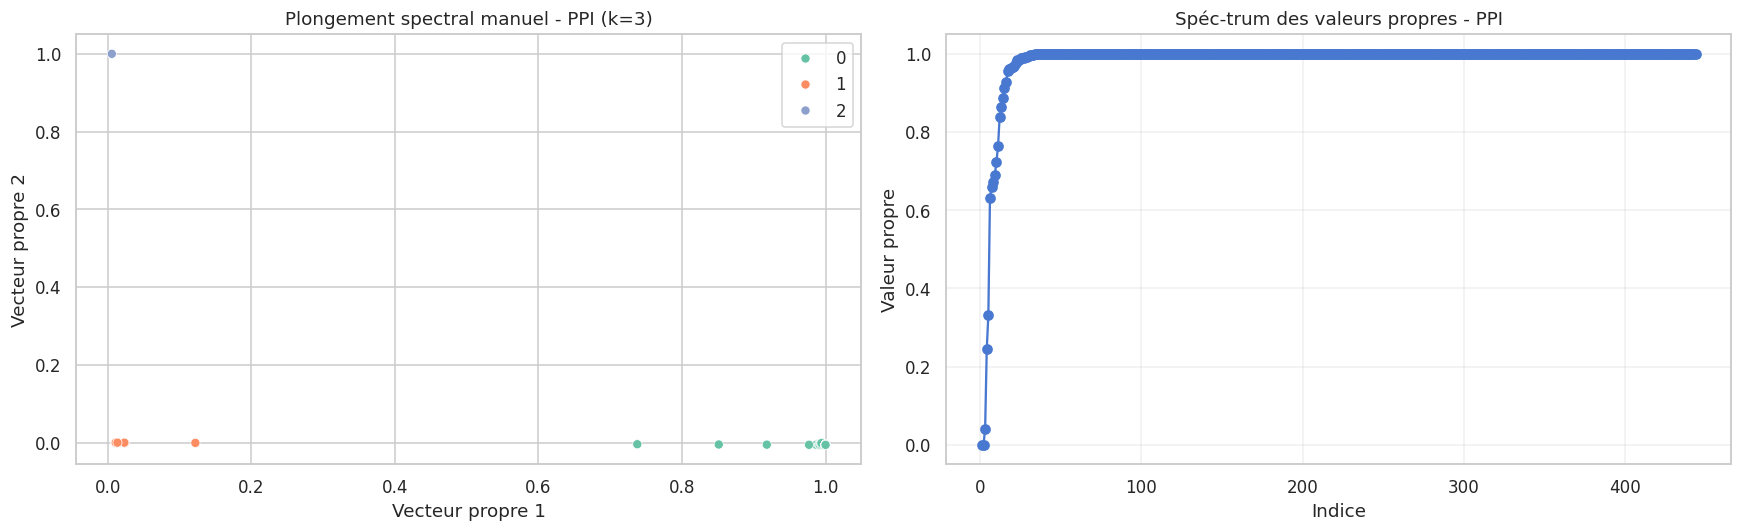

In [6]:
family_demo = list(descriptor_families.keys())[0]  # Choisir une famille représentative
cols = descriptor_families[family_demo]
X_family = X_scaled[cols].values
k_demo = 3
kmeans_demo, labels_demo, embedding_demo, eigenvalues_demo, W_demo, L_demo = spectral_clustering_manual(X_family, k_demo, gamma=1.0/max(len(cols), 1))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.scatterplot(x=embedding_demo[:, 0], y=embedding_demo[:, 1], hue=labels_demo, palette='Set2', ax=axes[0], legend='full')
axes[0].set_title(f'Plongement spectral manuel - {family_demo} (k={k_demo})')
axes[0].set_xlabel('Vecteur propre 1')
axes[0].set_ylabel('Vecteur propre 2')

axes[1].plot(np.arange(1, len(eigenvalues_demo) + 1), eigenvalues_demo, marker='o')
axes[1].set_title(f'Spéc-trum des valeurs propres - {family_demo}')
axes[1].set_xlabel('Indice')
axes[1].set_ylabel('Valeur propre')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()
